# LeetCode #140: Word Break II

https://leetcode.com/problems/word-break-ii/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Backtracking | O(n * 2^n) | O(n * 2^n) |
| Backtracking + Memoization ★ | O(n^2 * 2^n) | O(n * 2^n) |

## Understanding the Methods
### Brute Force (Backtracking)
Enumerate all possible segmentations using DFS. At each position, try all dictionary words that match. Collect complete sentences when the end of the string is reached.

### Optimal: Backtracking + Memoization ★
Cache results at each starting position: memo[i] = list of all sentences possible from s[i:]. Avoid re-computing the same suffixes. Still exponential in worst case (many valid sentences), but avoids redundant work in overlapping subproblems.

## Solutions
### C#

In [ ]:
// Backtracking + Memoization
public class Solution {
    private Dictionary<int, List<string>> memo = new();
    private HashSet<string> wordSet;
    private string s;

    public IList<string> WordBreak(string s, IList<string> wordDict) {
        this.s = s;
        wordSet = new HashSet<string>(wordDict);
        return Dfs(0);
    }

    private List<string> Dfs(int start) {
        if (memo.ContainsKey(start)) return memo[start];
        var result = new List<string>();
        if (start == s.Length) { result.Add(""); return result; }
        for (int end = start + 1; end <= s.Length; end++) {
            string word = s.Substring(start, end - start);
            if (wordSet.Contains(word)) {
                foreach (var rest in Dfs(end))
                    result.Add(word + (rest == "" ? "" : " " + rest));
            }
        }
        memo[start] = result;
        return result;
    }
}

### Python

In [ ]:
# Backtracking + Memoization
from functools import lru_cache

class Solution:
    def wordBreak(self, s: str, wordDict: list[str]) -> list[str]:
        word_set = set(wordDict)

        @lru_cache(maxsize=None)
        def dfs(start: int) -> list[str]:
            if start == len(s):
                return [""]
            result = []
            for end in range(start + 1, len(s) + 1):
                word = s[start:end]
                if word in word_set:
                    for rest in dfs(end):
                        result.append(word if rest == "" else word + " " + rest)
            return result

        return dfs(0)

### Go

In [ ]:
// Backtracking + Memoization
func wordBreak(s string, wordDict []string) []string {
    wordSet := make(map[string]bool)
    for _, w := range wordDict { wordSet[w] = true }
    memo := make(map[int][]string)

    var dfs func(start int) []string
    dfs = func(start int) []string {
        if v, ok := memo[start]; ok { return v }
        if start == len(s) { return []string{""} }
        var result []string
        for end := start + 1; end <= len(s); end++ {
            word := s[start:end]
            if wordSet[word] {
                for _, rest := range dfs(end) {
                    if rest == "" { result = append(result, word) } else {
                        result = append(result, word+" "+rest)
                    }
                }
            }
        }
        memo[start] = result
        return result
    }
    return dfs(0)
}

### Rust

In [ ]:
// Backtracking + Memoization
use std::collections::{HashMap, HashSet};

impl Solution {
    pub fn word_break(s: String, word_dict: Vec<String>) -> Vec<String> {
        let word_set: HashSet<&str> = word_dict.iter().map(|w| w.as_str()).collect();
        let mut memo: HashMap<usize, Vec<String>> = HashMap::new();
        Self::dfs(&s, 0, &word_set, &mut memo)
    }

    fn dfs(s: &str, start: usize, word_set: &HashSet<&str>, memo: &mut HashMap<usize, Vec<String>>) -> Vec<String> {
        if let Some(v) = memo.get(&start) { return v.clone(); }
        let mut result = Vec::new();
        if start == s.len() { result.push(String::new()); return result; }
        for end in (start+1)..=s.len() {
            let word = &s[start..end];
            if word_set.contains(word) {
                for rest in Self::dfs(s, end, word_set, memo) {
                    let sentence = if rest.is_empty() { word.to_string() } else { format!("{} {}", word, rest) };
                    result.push(sentence);
                }
            }
        }
        memo.insert(start, result.clone());
        result
    }
}

## Example Scenarios

### 1. Common Case — two valid segmentations
**Input:** s = "catsanddog", wordDict = ["cat","cats","and","sand","dog"]
DFS from index 0 branches on "cat" and "cats". The "cat"&rarr;"sand"&rarr;"dog" path and the "cats"&rarr;"and"&rarr;"dog" path both reach the end. Result **["cat sand dog", "cats and dog"]**.

### 2. Slightly Complex — overlapping words, three answers
**Input:** s = "pineapplepenapple", wordDict = ["apple","pen","applepen","pine","pineapple"]
Branches on "pine" vs "pineapple", and later "apple"+"pen" vs "applepen", yielding three complete sentences. Memoization on the start index avoids re-exploring shared suffixes.

### 3. Edge Case: Time Factor — every branch dead-ends
**Input:** s = "catsandog", wordDict = ["cats","dog","sand","and","cat"]
Several promising prefixes ("cat", "cats", "sand", "and") are tried, but every path stalls on the uncoverable "og". All branches are pruned &rarr; **[]**.

### 4. Edge Case: Space Factor — single word
**Input:** s = "a", wordDict = ["a"]
One branch, one word, immediate completion. The result list holds a single sentence **["a"]**.

### 5. Almost-Impossible but Plausible — exponential blowup
**Input:** s = "aaa", wordDict = ["a","aa","aaa"]
Every way to tile the a's is valid, so the answer count grows exponentially with length: "a a a", "a aa", "aa a", "aaa" — four sentences from just three characters.


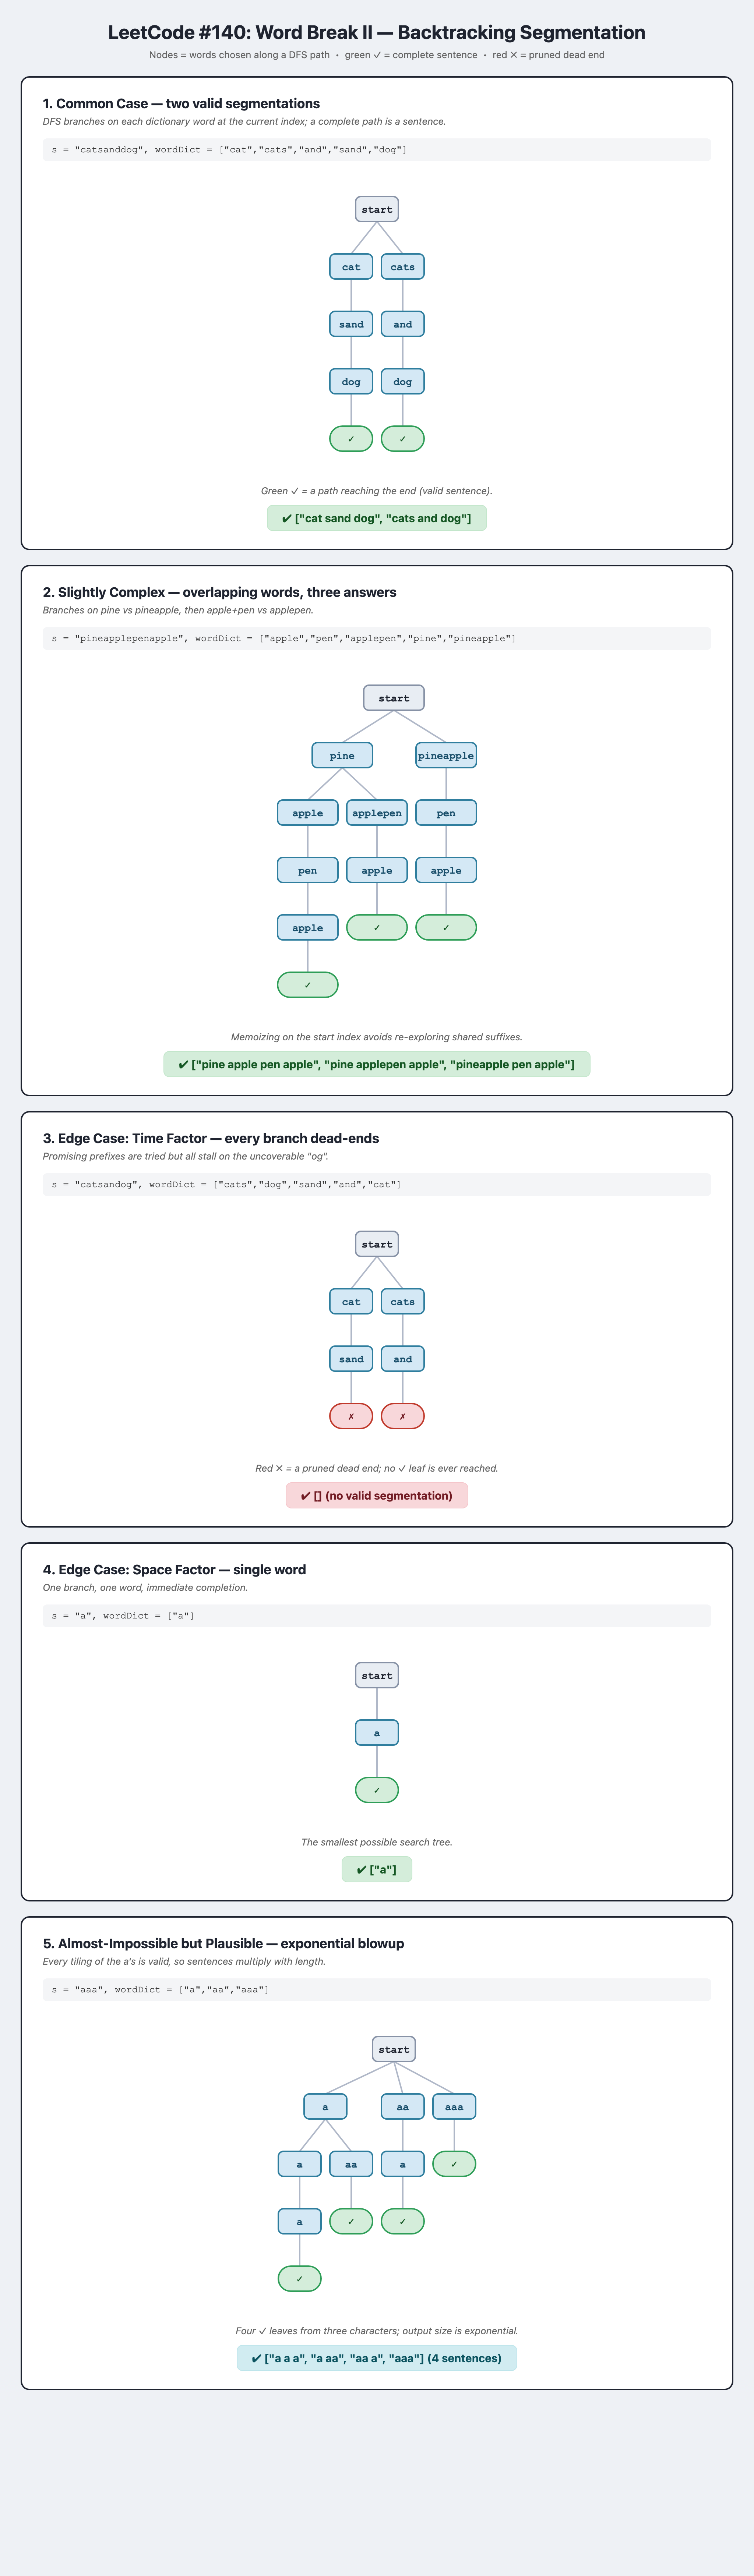